# F26-16: Turbofan Engine Remaining Useful Life (RUL) Prediction with Uncertainty Quantification
**Dataset:** NASA C-MAPSS (`FD001`)  
**Models:** Random Forest, Gradient Boosting, Stacked LSTM with Monte Carlo Dropout, and Deep Ensemble  
**Evaluation Metrics:** RMSE, MAE, NASA PHM08 Asymmetric Score, 95% PICP, 95% MPIW, and Calibration Curves

## 1. Environment Setup, Reproducibility Seeds & Google Drive Mount
Sets deterministic random seeds across Python, NumPy, and TensorFlow, verifies T4 GPU availability, and mounts Google Drive.

In [9]:
import os
import glob
import json
import random
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Set deterministic seeds
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Locate and extract the outer and inner zip files
DRIVE_DATA_DIR = '/content/drive/MyDrive/RUL_project/data'
EXTRACT_DIR = '/content/CMAPSSData'
ARTIFACT_PATH = '/content/drive/MyDrive/RUL_project/artifacts/'
os.makedirs(EXTRACT_DIR, exist_ok=True)
os.makedirs(ARTIFACT_PATH, exist_ok=True)

outer_zips = glob.glob(f"{DRIVE_DATA_DIR}/*.zip")
if not outer_zips:
    raise FileNotFoundError(f"No .zip file found in {DRIVE_DATA_DIR}")

with zipfile.ZipFile(outer_zips[0], 'r') as zf:
    zf.extractall(EXTRACT_DIR)

# Extract any nested zip files (e.g., CMAPSSData.zip)
for inner_zip in glob.glob(f"{EXTRACT_DIR}/**/*.zip", recursive=True):
    with zipfile.ZipFile(inner_zip, 'r') as zf:
        zf.extractall(EXTRACT_DIR)

# Find the exact directory containing train_FD001.txt
matches = glob.glob(f"{EXTRACT_DIR}/**/train_FD001.txt", recursive=True)
if not matches:
    raise FileNotFoundError("train_FD001.txt not found after extracting nested zip!")

DATA_PATH = os.path.dirname(matches[0]) + '/'
print("Resolved DATA_PATH:", DATA_PATH)
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resolved DATA_PATH: /content/CMAPSSData/
TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading, Feature Filtering, Scaling & Piecewise-Linear RUL Cap
* Applies a **125-cycle piecewise-linear RUL cap** on training targets.
* Identifies and drops **zero/near-zero variance sensors** strictly on the training data.
* Splits engines **80/20 by `unit_id`** before windowing to eliminate data leakage across overlapping windows.
* Fits `MinMaxScaler(0, 1)` strictly on training engines and transforms validation and test engines consistently.
* Exports `scaler_FD001.pkl` and `features_FD001.json` for FastAPI/Streamlit deployment.

In [10]:
# Configuration parameters per Proposal (FD001)
DATASET_ID = 'FD001'
WINDOW_SIZE = 30
RUL_CAP = 125

# Column definitions for NASA C-MAPSS
index_cols = ['unit_id', 'time_cycles']
setting_cols = ['setting_1', 'setting_2', 'setting_3']
sensor_cols = [f's_{i}' for i in range(1, 22)]
all_cols = index_cols + setting_cols + sensor_cols

# 1. Load raw train, test, and ground-truth RUL files
train_df = pd.read_csv(f"{DATA_PATH}train_{DATASET_ID}.txt", sep=r'\s+', header=None, names=all_cols)
test_df = pd.read_csv(f"{DATA_PATH}test_{DATASET_ID}.txt", sep=r'\s+', header=None, names=all_cols)
rul_df = pd.read_csv(f"{DATA_PATH}RUL_{DATASET_ID}.txt", sep=r'\s+', header=None, names=['RUL'])

# 2. Compute Piecewise-Linear Capped RUL for Training Set
max_cycles = train_df.groupby('unit_id')['time_cycles'].max().reset_index()
max_cycles.columns = ['unit_id', 'max_cycle']
train_df = train_df.merge(max_cycles, on='unit_id', how='left')
train_df['RUL'] = (train_df['max_cycle'] - train_df['time_cycles']).clip(upper=RUL_CAP)
train_df.drop(columns=['max_cycle'], inplace=True)

# 3. Identify & Drop Zero/Near-Zero Variance Features strictly on Training Set
candidate_features = setting_cols + sensor_cols
stds = train_df[candidate_features].std()
dropped_features = stds[stds < 1e-5].index.tolist()
selected_features = [col for col in candidate_features if col not in dropped_features]

print(f"Dropped {len(dropped_features)} constant features: {dropped_features}")
print(f"Retained {len(selected_features)} informative features: {selected_features}")

# 4. Engine-Level Train/Validation Split (prevents overlapping window leakage)
unique_engines = train_df['unit_id'].unique()
train_engines, val_engines = train_test_split(unique_engines, test_size=0.2, random_state=SEED)

train_split_df = train_df[train_df['unit_id'].isin(train_engines)].copy()
val_split_df = train_df[train_df['unit_id'].isin(val_engines)].copy()

# 5. Fit MinMaxScaler ONLY on Training Engines, then transform Val and Test
scaler = MinMaxScaler(feature_range=(0, 1))
train_split_df[selected_features] = scaler.fit_transform(train_split_df[selected_features])
val_split_df[selected_features] = scaler.transform(val_split_df[selected_features])
test_df[selected_features] = scaler.transform(test_df[selected_features])

# Save scaler & metadata for downstream FastAPI / Streamlit deployment
joblib.dump(scaler, f"{ARTIFACT_PATH}scaler_{DATASET_ID}.pkl")
with open(f"{ARTIFACT_PATH}features_{DATASET_ID}.json", "w") as f:
    json.dump({
        "dataset": DATASET_ID,
        "window_size": WINDOW_SIZE,
        "rul_cap": RUL_CAP,
        "selected_features": selected_features,
        "dropped_features": dropped_features
    }, f, indent=2)

print(f"Train engines: {len(train_engines)} | Val engines: {len(val_engines)} | Test engines: {test_df['unit_id'].nunique()}")

Dropped 7 constant features: ['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']
Retained 17 informative features: ['setting_1', 'setting_2', 's_2', 's_3', 's_4', 's_6', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
Train engines: 80 | Val engines: 20 | Test engines: 100


## 3. Sliding Window Sequence Generation
Converts engine timelines into 3D sequences of shape `(samples, 30, 17)` for LSTM modeling, using the last 30 cycles of each test engine (with left-padding if any sequence is shorter than 30 cycles) and clipping test RUL targets at 125 cycles.

In [11]:
def create_train_windows(df, window_size, features):
    X, y = [], []
    for _, group in df.groupby('unit_id'):
        data_arr = group[features].values
        rul_arr = group['RUL'].values
        if len(group) >= window_size:
            for i in range(len(group) - window_size + 1):
                X.append(data_arr[i : i + window_size])
                y.append(rul_arr[i + window_size - 1])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

def create_test_windows(df, rul_ground_truth, window_size, features, rul_cap=125):
    X, y = [], []
    for idx, (_, group) in enumerate(df.groupby('unit_id')):
        data_arr = group[features].values
        if len(data_arr) >= window_size:
            X.append(data_arr[-window_size:])
        else:
            pad_len = window_size - len(data_arr)
            pad = np.repeat(data_arr[0:1], pad_len, axis=0)
            X.append(np.vstack([pad, data_arr]))
        y.append(min(rul_ground_truth.iloc[idx, 0], rul_cap))
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

X_train, y_train = create_train_windows(train_split_df, WINDOW_SIZE, selected_features)
X_val, y_val = create_train_windows(val_split_df, WINDOW_SIZE, selected_features)
X_test, y_test = create_test_windows(test_df, rul_df, WINDOW_SIZE, selected_features, rul_cap=RUL_CAP)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}   | y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

X_train shape: (14241, 30, 17) | y_train shape: (14241,)
X_val shape:   (3490, 30, 17)   | y_val shape:   (3490,)
X_test shape:  (100, 30, 17)  | y_test shape:  (100,)


## 4. Evaluation Metrics Suite (Point Accuracy, NASA PHM08 Score & UQ Coverage)
Defines:
* **RMSE & MAE:** Standard point-prediction error metrics.
* **NASA Asymmetric Score:** Penalizes late failure predictions ($\hat{y} \ge y$) exponentially harder than early predictions ($\hat{y} < y$).
* **PICP & MPIW:** Prediction Interval Coverage Probability and Mean Prediction Interval Width for 95% confidence bounds.

In [12]:
def nasa_asymmetric_score(y_true, y_pred):
    """
    Official NASA PHM08 Asymmetric Scoring Function:
    Penalizes late predictions (d >= 0, overestimating RUL) more heavily than early predictions (d < 0).
    """
    d = y_pred - y_true
    scores = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(scores))

def evaluate_point_predictions(y_true, y_pred, model_name="Model"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    nasa_score = nasa_asymmetric_score(y_true, y_pred)
    print(f"[{model_name}] RMSE: {rmse:.2f} | MAE: {mae:.2f} | NASA Score: {nasa_score:.2f}")
    return {"Model": model_name, "RMSE": rmse, "MAE": mae, "NASA_Score": nasa_score}

def evaluate_uncertainty(y_true, y_mean, y_std, alpha=0.05):
    """
    Computes Prediction Interval Coverage Probability (PICP) and Mean Prediction Interval Width (MPIW)
    for a 95% Gaussian prediction interval (z = 1.96).
    """
    z = 1.96
    lower = y_mean - z * y_std
    upper = y_mean + z * y_std

    in_interval = (y_true >= lower) & (y_true <= upper)
    picp = np.mean(in_interval) * 100.0
    mpiw = np.mean(upper - lower)
    return picp, mpiw, lower, upper

## 5. Classical Machine Learning Baselines (Hand-Engineered Window Features)
Extracts 6 summary statistics per sensor across each 30-cycle window (**mean, std, min, max, last reading, and linear slope**) to benchmark **Random Forest** and **Gradient Boosting** regressors against the deep learning models.

In [13]:
def extract_statistical_features(X_3d):
    """
    Extracts domain-relevant summary statistics per sensor across the 30-cycle window:
    mean, std, min, max, last value, and linear slope (trend).
    """
    n_samples, seq_len, n_features = X_3d.shape
    t = np.arange(seq_len)
    t_centered = t - t.mean()
    denom = np.sum(t_centered ** 2)

    feat_mean = np.mean(X_3d, axis=1)
    feat_std = np.std(X_3d, axis=1)
    feat_min = np.min(X_3d, axis=1)
    feat_max = np.max(X_3d, axis=1)
    feat_last = X_3d[:, -1, :]
    feat_slope = np.einsum('ijk,j->ik', X_3d - feat_mean[:, None, :], t_centered) / denom

    return np.hstack([feat_mean, feat_std, feat_min, feat_max, feat_last, feat_slope])

X_train_tab = extract_statistical_features(X_train)
X_test_tab = extract_statistical_features(X_test)

results_summary = []

# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train_tab, y_train)
rf_preds = rf_model.predict(X_test_tab)
results_summary.append(evaluate_point_predictions(y_test, rf_preds, "Random Forest (Engineered Features)"))

# 2. Gradient Boosting Regressor
gbr_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=SEED)
gbr_model.fit(X_train_tab, y_train)
gbr_preds = gbr_model.predict(X_test_tab)
results_summary.append(evaluate_point_predictions(y_test, gbr_preds, "Gradient Boosting (Engineered Features)"))

[Random Forest (Engineered Features)] RMSE: 13.33 | MAE: 9.43 | NASA Score: 308.98
[Gradient Boosting (Engineered Features)] RMSE: 12.42 | MAE: 9.30 | NASA Score: 244.50


## 6. Deep Learning Architecture & Training (cuDNN-Accelerated Stacked LSTM)
Uses explicit `Dropout(0.2)` layers between LSTM layers (avoiding `recurrent_dropout` so NVIDIA cuDNN GPU kernels stay active for ~1–2s epochs) with `EarlyStopping` and `ReduceLROnPlateau` callbacks.

In [14]:
def build_lstm_uq_model(input_shape, dropout_rate=0.2, lr=1e-3):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(dropout_rate),
        layers.LSTM(32, return_sequences=False),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(1)
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='mse',
        metrics=['mae']
    )
    return model

input_shape = (WINDOW_SIZE, len(selected_features))
mc_lstm_model = build_lstm_uq_model(input_shape, dropout_rate=0.2, lr=1e-3)
mc_lstm_model.summary()

train_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1)
]

history = mc_lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=80,
    batch_size=64,
    callbacks=train_callbacks,
    verbose=1
)

# Save primary MC-Dropout LSTM model
mc_lstm_model.save(f"{ARTIFACT_PATH}lstm_mc_dropout_{DATASET_ID}.keras")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,497 (134.75 KB)

 Trainable params: 34,497 (134.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 4694.7842 - mae: 57.9698 - val_loss: 1885.3757 - val_mae: 38.8119 - learning_rate: 0.0010
Epoch 2/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 1906.9958 - mae: 38.3784 - val_loss: 1744.1873 - val_mae: 37.1412 - learning_rate: 0.0010
Epoch 3/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 1882.4247 - mae: 38.0147 - val_loss: 1744.1548 - val_mae: 37.1398 - learning_rate: 0.0010
Epoch 4/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1887.7330 - mae: 38.1078 - val_loss: 1743.8000 - val_mae: 37.1206 - learning_rate: 0.0010
Epoch 5/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1883.9639 - mae: 38.0505 - val_loss: 1744.6477 - val_mae: 37.1636 - learning_rate: 0.0010
Epoch 6/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 1879.6133 - mae: 38.0102 - val_loss: 1744.5394 - val_mae: 37.1626 - learning_rate: 0.0010
Epoch 7/80
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 1872.0162 - mae: 37.9518 - val_loss:

## 7. Uncertainty Quantification Method A: Monte Carlo Dropout ($T = 100$ Passes)
Runs 100 stochastic forward passes with `training=True` during inference to approximate the predictive posterior mean and epistemic uncertainty ($\sigma$).

In [15]:
@tf.function
def mc_forward_pass(model, x):
    return model(x, training=True)

def predict_mc_dropout(model, X_data, n_iter=100):
    preds = np.array([mc_forward_pass(model, X_data).numpy().flatten() for _ in range(n_iter)])
    mean_pred = np.mean(preds, axis=0)
    std_pred = np.std(preds, axis=0)
    return mean_pred, std_pred, preds

mc_mean, mc_std, mc_samples = predict_mc_dropout(mc_lstm_model, X_test, n_iter=100)
mc_metrics = evaluate_point_predictions(y_test, mc_mean, "LSTM + MC Dropout (T=100)")
mc_picp, mc_mpiw, mc_lower, mc_upper = evaluate_uncertainty(y_test, mc_mean, mc_std)

mc_metrics["PICP_95 (%)"] = mc_picp
mc_metrics["MPIW_95 (Cycles)"] = mc_mpiw
results_summary.append(mc_metrics)

print(f"[MC Dropout UQ] 95% PICP: {mc_picp:.2f}% (Target: 95.00%) | 95% MPIW: {mc_mpiw:.2f} cycles")

[LSTM + MC Dropout (T=100)] RMSE: 13.79 | MAE: 9.95 | NASA Score: 412.86
[MC Dropout UQ] 95% PICP: 85.00% (Target: 95.00%) | 95% MPIW: 39.77 cycles


## 8. Uncertainty Quantification Method B: Deep Ensemble ($M = 5$ Models)
Trains 5 independently initialized LSTM models from different random seeds and aggregates their test predictions to compare Deep Ensemble uncertainty against MC Dropout.

In [16]:
N_ENSEMBLE = 5
ensemble_models = []
ensemble_preds = []

print(f"Training Deep Ensemble ({N_ENSEMBLE} independently initialized LSTM models)...")
for m in range(N_ENSEMBLE):
    tf.keras.utils.set_random_seed(SEED + m * 100)
    member = build_lstm_uq_model(input_shape, dropout_rate=0.15, lr=1e-3)

    es = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)
    rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0)

    member.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=60,
        batch_size=64,
        callbacks=[es, rlr],
        verbose=0
    )
    member.save(f"{ARTIFACT_PATH}ensemble_member_{m}_{DATASET_ID}.keras")
    ensemble_models.append(member)

    pred_m = member.predict(X_test, verbose=0).flatten()
    ensemble_preds.append(pred_m)
    print(f"  Member {m+1}/{N_ENSEMBLE} Test RMSE: {np.sqrt(mean_squared_error(y_test, pred_m)):.2f}")

ensemble_preds = np.array(ensemble_preds)
ens_mean = np.mean(ensemble_preds, axis=0)
ens_std = np.std(ensemble_preds, axis=0)

ens_metrics = evaluate_point_predictions(y_test, ens_mean, f"Deep Ensemble (M={N_ENSEMBLE})")
ens_picp, ens_mpiw, ens_lower, ens_upper = evaluate_uncertainty(y_test, ens_mean, ens_std)

ens_metrics["PICP_95 (%)"] = ens_picp
ens_metrics["MPIW_95 (Cycles)"] = ens_mpiw
results_summary.append(ens_metrics)

print(f"[Deep Ensemble UQ] 95% PICP: {ens_picp:.2f}% (Target: 95.00%) | 95% MPIW: {ens_mpiw:.2f} cycles")

Training Deep Ensemble (5 independently initialized LSTM models)...
  Member 1/5 Test RMSE: 12.96
  Member 2/5 Test RMSE: 13.15


  Member 3/5 Test RMSE: 13.30
  Member 4/5 Test RMSE: 13.48
  Member 5/5 Test RMSE: 13.02
[Deep Ensemble (M=5)] RMSE: 12.99 | MAE: 9.56 | NASA Score: 309.55
[Deep Ensemble UQ] 95% PICP: 27.00% (Target: 95.00%) | 95% MPIW: 7.76 cycles


## 9. Consolidated Benchmark Table & Visualizations
Generates:
1. Summary comparison table across all baselines and UQ models.
2. Training vs. validation MSE loss curve.
3. Sorted test engine RUL predictions with **95% Confidence Intervals** (MC Dropout vs. Deep Ensemble).
4. **Uncertainty Calibration Curve** comparing expected confidence levels against empirical coverage probability.


=== FINAL MODEL & UNCERTAINTY BENCHMARK (FD001) ===
                                  Model      RMSE      MAE  NASA_Score  PICP_95 (%)  MPIW_95 (Cycles)
    Random Forest (Engineered Features) 13.331471 9.431496  308.977670          NaN               NaN
Gradient Boosting (Engineered Features) 12.422407 9.295081  244.495701          NaN               NaN
              LSTM + MC Dropout (T=100) 13.790158 9.948416  412.857147         85.0         39.772003
                    Deep Ensemble (M=5) 12.989732 9.564220  309.551788         27.0          7.761627


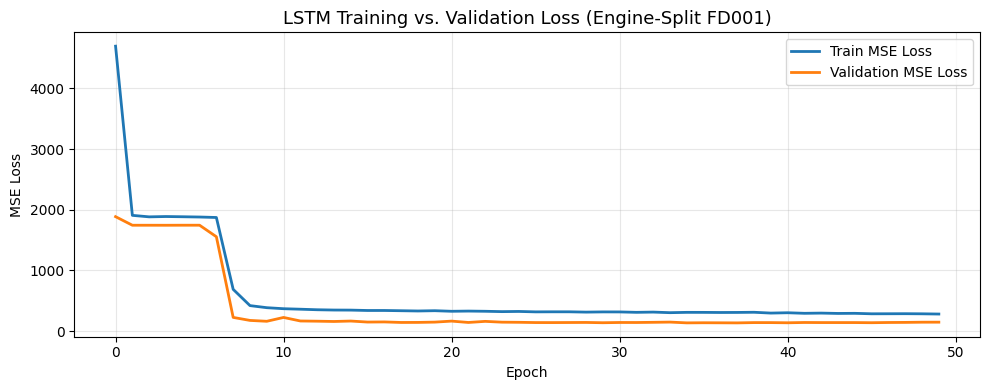

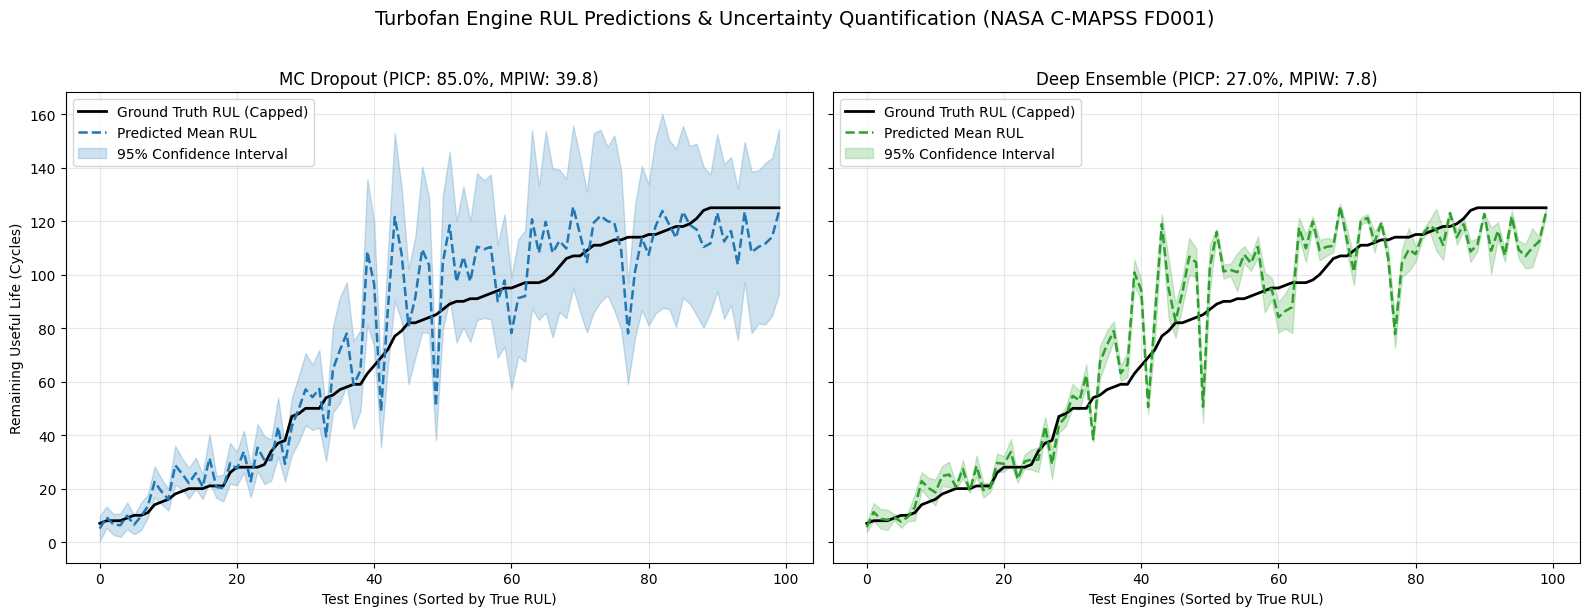

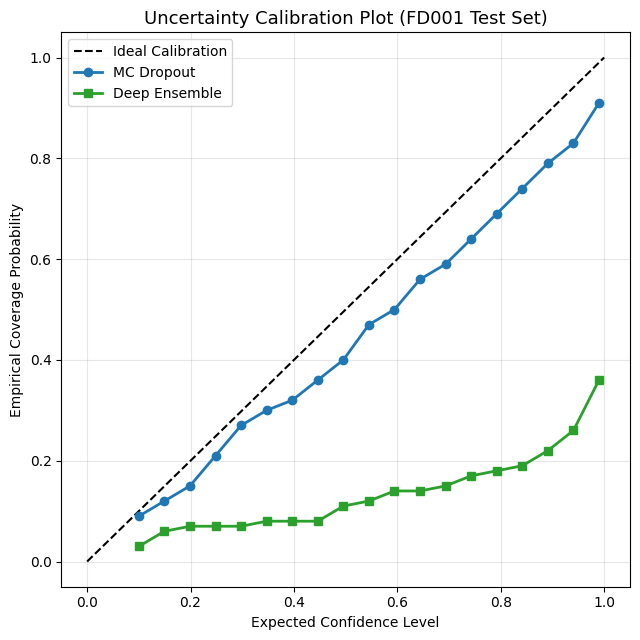

In [17]:
# 1. Print Consolidated Benchmark Table
summary_df = pd.DataFrame(results_summary)
print("\n=== FINAL MODEL & UNCERTAINTY BENCHMARK (FD001) ===")
print(summary_df.to_string(index=False))

# 2. Plot Training & Validation Loss Curve
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train MSE Loss', lw=2)
plt.plot(history.history['val_loss'], label='Validation MSE Loss', lw=2)
plt.title('LSTM Training vs. Validation Loss (Engine-Split FD001)', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Sorted RUL Predictions with 95% Confidence Intervals (MC Dropout vs Deep Ensemble)
sorted_idx = np.argsort(y_test)
y_true_s = y_test[sorted_idx]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, title, mean_arr, low_arr, high_arr, color in [
    (axes[0], f"MC Dropout (PICP: {mc_picp:.1f}%, MPIW: {mc_mpiw:.1f})", mc_mean[sorted_idx], mc_lower[sorted_idx], mc_upper[sorted_idx], 'tab:blue'),
    (axes[1], f"Deep Ensemble (PICP: {ens_picp:.1f}%, MPIW: {ens_mpiw:.1f})", ens_mean[sorted_idx], ens_lower[sorted_idx], ens_upper[sorted_idx], 'tab:green')
]:
    ax.plot(y_true_s, color='black', lw=2, label='Ground Truth RUL (Capped)')
    ax.plot(mean_arr, color=color, linestyle='--', lw=1.8, label='Predicted Mean RUL')
    ax.fill_between(range(len(y_true_s)), low_arr, high_arr, color=color, alpha=0.22, label='95% Confidence Interval')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Test Engines (Sorted by True RUL)')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')

axes[0].set_ylabel('Remaining Useful Life (Cycles)')
plt.suptitle('Turbofan Engine RUL Predictions & Uncertainty Quantification (NASA C-MAPSS FD001)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 4. Uncertainty Calibration Curve (Expected Confidence vs Empirical Coverage)
confidence_levels = np.linspace(0.10, 0.99, 19)
mc_empirical = []
ens_empirical = []

for conf in confidence_levels:
    z_val = norm.ppf(0.5 + conf / 2.0)
    mc_cov = np.mean((y_test >= mc_mean - z_val * mc_std) & (y_test <= mc_mean + z_val * mc_std))
    ens_cov = np.mean((y_test >= ens_mean - z_val * ens_std) & (y_test <= ens_mean + z_val * ens_std))
    mc_empirical.append(mc_cov)
    ens_empirical.append(ens_cov)

plt.figure(figsize=(6.5, 6.5))
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Ideal Calibration')
plt.plot(confidence_levels, mc_empirical, 'o-', color='tab:blue', lw=2, label='MC Dropout')
plt.plot(confidence_levels, ens_empirical, 's-', color='tab:green', lw=2, label='Deep Ensemble')
plt.title('Uncertainty Calibration Plot (FD001 Test Set)', fontsize=13)
plt.xlabel('Expected Confidence Level')
plt.ylabel('Empirical Coverage Probability')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Single-Engine Production Inference Helper (FastAPI / Streamlit Ready)
Demonstrates risk-aware maintenance scheduling using the saved `.keras`, `.pkl`, and `.json` artifacts on an individual engine's raw sensor history.

In [18]:
def predict_single_engine_rul(engine_sensor_df, model, scaler, selected_features, window_size=30, n_iter=100, safety_threshold=20):
    """
    Production inference function for a single turbofan engine's recent cycle history.
    """
    scaled_vals = scaler.transform(engine_sensor_df[selected_features])
    if len(scaled_vals) < window_size:
        pad = np.repeat(scaled_vals[0:1], window_size - len(scaled_vals), axis=0)
        window = np.vstack([pad, scaled_vals])
    else:
        window = scaled_vals[-window_size:]

    X_input = np.expand_dims(window, axis=0).astype(np.float32)
    preds = np.array([model(X_input, training=True).numpy()[0, 0] for _ in range(n_iter)])

    mean_rul = float(np.mean(preds))
    std_rul = float(np.std(preds))
    lower_95 = max(0.0, mean_rul - 1.96 * std_rul)
    upper_95 = mean_rul + 1.96 * std_rul

    # Risk-aware maintenance trigger using the lower 95% bound
    action = "SCHEDULE IMMEDIATE MAINTENANCE" if lower_95 <= safety_threshold else "NORMAL OPERATION"
    return {
        "predicted_rul": round(mean_rul, 2),
        "uncertainty_std": round(std_rul, 2),
        "ci_95_lower": round(lower_95, 2),
        "ci_95_upper": round(upper_95, 2),
        "maintenance_status": action
    }

# Simulate raw API input on Engine #34 from test_FD001
raw_test_df = pd.read_csv(f"{DATA_PATH}test_{DATASET_ID}.txt", sep=r'\s+', header=None, names=all_cols)
raw_engine_34 = raw_test_df[raw_test_df['unit_id'] == 34]

result = predict_single_engine_rul(raw_engine_34, mc_lstm_model, scaler, selected_features)
print(f"Engine #34 True RUL: {min(rul_df.iloc[33, 0], RUL_CAP)} cycles")
print("Inference Output:", json.dumps(result, indent=2))

Engine #34 True RUL: 7 cycles
Inference Output: {
  "predicted_rul": 4.81,
  "uncertainty_std": 2.29,
  "ci_95_lower": 0.31,
  "ci_95_upper": 9.3,
  "maintenance_status": "SCHEDULE IMMEDIATE MAINTENANCE"
}


In [19]:
import shutil
from google.colab import files

export_dir = '/content/best_rul_model_bundle'
os.makedirs(export_dir, exist_ok=True)

shutil.copy(f"{ARTIFACT_PATH}scaler_{DATASET_ID}.pkl", export_dir)
shutil.copy(f"{ARTIFACT_PATH}features_{DATASET_ID}.json", export_dir)
shutil.copy(f"{ARTIFACT_PATH}lstm_mc_dropout_{DATASET_ID}.keras", export_dir)

zip_path = shutil.make_archive('/content/RUL_MC_Dropout_Bundle', 'zip', export_dir)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>